# 22장 · 화학 퍼텐셜 — 예제 풀이

**열및통계물리2 · 교재 22장 화학 퍼텐셜 (Blundell & Blundell, *Concepts in Thermal Physics* 2판)**

교재 예제 22.1–22.8과 추가 문제(연습문제 22.6, 22.7)를 Python으로 확인한다. 위에서부터 순서대로 실행하면 된다.
기호는 강의자료를 따라 큰분배함수를 $\Xi$(교재 $\mathcal Z$)로 쓴다. 단위는 SI, 그래프 라벨은 영어로 쓴다.

In [1]:
# ── 0. 준비: 라이브러리와 물리 상수 ──────────────────────────────
import numpy as np
import scipy.constants as sc
from scipy import integrate, optimize, special
import matplotlib.pyplot as plt

# 물리 상수 (SI 단위). 출처: scipy.constants = CODATA 2018 권장값
kB   = sc.k            # 볼츠만 상수 [J/K]
h    = sc.h            # 플랑크 상수 [J s]
hbar = sc.hbar         # [J s]
c    = sc.c            # 광속 [m/s]
e    = sc.e            # 기본 전하 [C]  (1 eV = e J)
NA   = sc.N_A          # 아보가드로 수 [1/mol]
R    = sc.R            # 기체 상수 [J/(mol K)]
me   = sc.m_e          # 전자 질량 [kg]
mp   = sc.m_p          # 양성자 질량 [kg]
amu  = sc.atomic_mass  # 원자 질량 단위 u [kg]
muB  = sc.physical_constants['Bohr magneton'][0]   # 보어 자기량 [J/T]
mu0  = sc.mu_0         # 진공 투자율 [N/A^2]
sigma_SB = sc.Stefan_Boltzmann                      # 스테판-볼츠만 상수 [W m^-2 K^-4]

plt.rcParams.update({'figure.figsize': (6.4, 4.0), 'axes.grid': True, 'grid.alpha': 0.3})

def compare(label, value, book, unit='', rtol=0.05):
    """계산값과 교재 답을 나란히 출력한다. rtol: 허용 상대오차 (교재 답은 보통 유효숫자 2자리)."""
    rel = abs(value - book) / abs(book)
    flag = 'OK' if rel <= rtol else 'CHECK'
    print(f'{label}: computed = {value:.4g} {unit} | textbook = {book:.4g} {unit} | rel. diff = {rel:.2%} [{flag}]')
    return rel

print('Setup complete. numpy', np.__version__)

Setup complete. numpy 2.5.3


## 예제 22.1 — 이상기체의 화학 퍼텐셜 (교재 318쪽)

**문제 요약.** $F=Nk_BT[\ln(n\lambda_{th}^3)-1]$ (22.13)을 $N$으로 미분해 $\mu=k_BT\ln(n\lambda_{th}^3)$ (22.15)를 얻고, 이것이 $G/N$과 같음을 확인한다.

**풀이 아이디어.** $F(N)$을 수치미분해 해석식과 비교한다. **가정(입력값):** N₂ 기체, $T=300$ K, $p=1$ bar.

In [2]:
m = 28.014 * amu                         # N2 분자 질량 [kg]
T, p = 300.0, 1e5                        # [K], [Pa]
V = 1e-3                                 # 부피 [m^3] (1 L)
N0 = p * V / (kB * T)                    # 분자 수
lam = lambda T: h / np.sqrt(2 * np.pi * m * kB * T)
F = lambda N: N * kB * T * (np.log(N / V * lam(T)**3) - 1)      # (22.13)
dN = N0 * 1e-6
mu_num = (F(N0 + dN) - F(N0 - dN)) / (2 * dN)
mu_formula = kB * T * np.log(N0 / V * lam(T)**3)                 # (22.15)
G = F(N0) + p * V                                                 # G = F + pV
print(f'n lambda^3 = {N0 / V * lam(T)**3:.3e}')
print(f'mu (numerical dF/dN) = {mu_num:.6e} J = {mu_num / (kB * T):.6f} k_B T')
print(f'mu (formula 22.15)   = {mu_formula:.6e} J = {mu_formula / (kB * T):.6f} k_B T')
print(f'G / N                = {G / N0:.6e} J')

n lambda^3 = 1.667e-07
mu (numerical dF/dN) = -6.464256e-20 J = -15.606805 k_B T
mu (formula 22.15)   = -6.464256e-20 J = -15.606805 k_B T
G / N                = -6.464256e-20 J


**해석.** 수치미분, 교재 식 (22.15), $G/N$ 세 값이 모두 같다(약 $-15.6\,k_BT$). 고전 기체는 $n\lambda_{th}^3\ll1$이므로 화학 퍼텐셜이 음수이다. $\mu=G/N$은 22.5절의 일반적 결과 (22.48)의 한 예이다.

## 예제 22.2 — 이상기체의 큰퍼텐셜 (교재 322–323쪽)

**문제 요약.** 이상기체에서 $\Phi_G=-Nk_BT=-pV$ (22.35, 22.36)임을 보이고, $(\partial\Phi_G/\partial\mu)_{T,V}=-N$ (22.38), $(\partial\Phi_G/\partial V)_{T,\mu}=-p$ (22.41)를 확인한다.

**풀이 아이디어.** $\mu$, $T$, $V$의 함수로 $N(\mu)=(V/\lambda^3)e^{\beta\mu}$를 쓰고 $\Phi_G=F-\mu N$을 계산해 수치미분한다.

In [3]:
def N_of(mu, V): return V / lam(T)**3 * np.exp(mu / (kB * T))      # mu = kT ln(n lam^3) 를 N 에 대해 푼 것
def PhiG(mu, V):
    N = N_of(mu, V); return F_gen(N, V) - mu * N                       # (22.29) Phi_G = F - mu N
def F_gen(N, V): return N * kB * T * (np.log(N / V * lam(T)**3) - 1)

mu0 = mu_formula
print(f'Phi_G = {PhiG(mu0, V):.6e} J,  -N k_B T = {-N0 * kB * T:.6e} J,  -pV = {-p * V:.6e} J')
dmu = abs(mu0) * 1e-7
print(f'dPhi/dmu = {(PhiG(mu0 + dmu, V) - PhiG(mu0 - dmu, V)) / (2 * dmu):.6e},  -N = {-N0:.6e}')
dV = V * 1e-7
print(f'dPhi/dV  = {(PhiG(mu0, V + dV) - PhiG(mu0, V - dV)) / (2 * dV):.6e} Pa,  -p = {-p:.6e} Pa')

Phi_G = -1.000000e+02 J,  -N k_B T = -1.000000e+02 J,  -pV = -1.000000e+02 J
dPhi/dmu = -2.414324e+22,  -N = -2.414324e+22
dPhi/dV  = -1.000000e+05 Pa,  -p = -1.000000e+05 Pa


**해석.** $\Phi_G=-Nk_BT=-pV$이고, 큰퍼텐셜을 $\mu$와 $V$로 미분하면 각각 $-N$, $-p$가 나온다(교재 식 22.32–22.34). 큰바른틀에서는 $T$, $V$, $\mu$가 자연 변수이다.

## 예제 22.3 — 화학 퍼텐셜의 압력 의존성 (교재 327쪽)

**문제 요약.** 온도가 일정할 때 $\mu=k_BT\ln(\lambda_{th}^3/k_BT)+k_BT\ln p$ (22.63)이므로 $\mu(p)=\mu^\ominus+k_BT\ln(p/p^\ominus)$ (22.64), 몰당 $\mu^\ominus+RT\ln(p/p^\ominus)$ (22.65)이다. 기준 $p^\ominus=1$ bar, 298 K.

**풀이 아이디어.** 여러 압력에서 몰당 $\mu$를 계산해 $\ln(p/p^\ominus)$에 대해 그리고, 기울기가 $RT$인지 확인한다.

mu_std (N2, 298 K, 1 bar) = -38.628 kJ/mol (translation only, zero of energy at rest)
slope d mu / d ln p = 2477.7099 J/mol,  R T = 2477.7099 J/mol


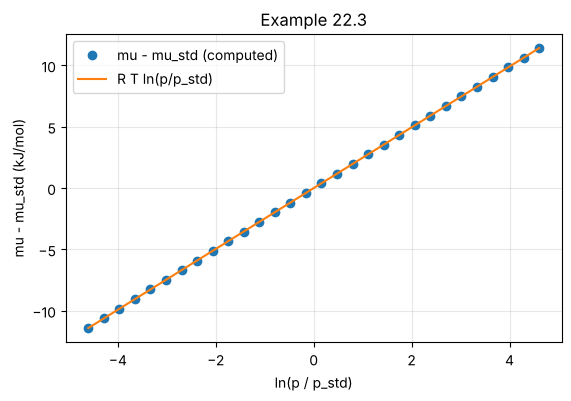

In [4]:
T = 298.0
ps = np.logspace(3, 7, 30)                                    # 1 kPa – 100 bar
mu_mol = NA * kB * T * np.log(ps / (kB * T) * lam(T)**3)      # 몰당 mu [J/mol]
pstd = 1e5
mu_std = NA * kB * T * np.log(pstd / (kB * T) * lam(T)**3)
slope = np.polyfit(np.log(ps / pstd), mu_mol, 1)[0]
print(f'mu_std (N2, 298 K, 1 bar) = {mu_std / 1e3:.3f} kJ/mol (translation only, zero of energy at rest)')
print(f'slope d mu / d ln p = {slope:.4f} J/mol,  R T = {R * T:.4f} J/mol')
plt.plot(np.log(ps / pstd), (mu_mol - mu_std) / 1e3, 'o', label='mu - mu_std (computed)')
plt.plot(np.log(ps / pstd), R * T * np.log(ps / pstd) / 1e3, '-', label='R T ln(p/p_std)')
plt.xlabel('ln(p / p_std)'); plt.ylabel('mu - mu_std (kJ/mol)'); plt.legend(); plt.title('Example 22.3'); plt.show()

**해석.** 기울기가 정확히 $RT$이다. 압력을 $e$배로 높이면 몰당 화학 퍼텐셜이 $RT\approx2.48$ kJ/mol만큼 커진다. 이 식이 화학 평형 상수 (22.80)의 출발점이다.

## 예제 22.4–22.6 — 암모니아 합성의 계수, 평형 조건, 평형상수 (교재 329–330쪽)

**문제 요약.** N₂ + 3H₂ → 2NH₃를 $0\to\sum_j\nu_jA_j$ (22.74)로 쓰면 $\nu=(-1,-3,+2)$ (22.76)이다. 평형 조건은 $\sum_j\nu_j\mu_j=0$ (22.79), 평형상수는 $K=\dfrac{(p_{\rm NH_3}/p^\ominus)^2}{(p_{\rm N_2}/p^\ominus)(p_{\rm H_2}/p^\ominus)^3}$ (22.81)이다.

**풀이 아이디어.** (1) 원자 보존을 행렬로 확인한다. (2) 몰당 $\mu_j=\mu_j^\ominus+RT\ln(p_j/p^\ominus)$이면 $\sum\nu_j\mu_j=\Delta_rG^\ominus+RT\ln Q$이고, 평형에서 $Q=K=e^{-\Delta_rG^\ominus/RT}$ (22.85)임을 임의의 $\Delta_rG^\ominus$로 확인한다.

In [5]:
species = ['N2', 'H2', 'NH3']
nu = np.array([-1, -3, 2])                         # (22.76)
atoms = np.array([[2, 0, 1],                       # N 원자 수 (행: 원소, 열: 화학종)
                  [0, 2, 3]])                      # H 원자 수
print('atom balance (N, H):', atoms @ nu, '(must be zero)')

def Q(pN2, pH2, pNH3, pstd=1.0):                   # (22.81) 의 형태 (압력: bar)
    return (pNH3 / pstd)**2 / ((pN2 / pstd) * (pH2 / pstd)**3)

dG_std = -10e3; T = 500.0                          # 임의의 값 [J/mol], [K] (계산 확인용)
K = np.exp(-dG_std / (R * T))
# 평형 조성 하나 만들기: pN2 = 1 bar, pH2 = 2 bar 로 두고 pNH3 를 K 에 맞춘다
pN2, pH2 = 1.0, 2.0
pNH3 = np.sqrt(K * pN2 * pH2**3)
sum_nu_mu = dG_std + R * T * np.log(Q(pN2, pH2, pNH3))
print(f'K = {K:.4f},  Q at chosen composition = {Q(pN2, pH2, pNH3):.4f},  sum nu_j mu_j = {sum_nu_mu:.2e} J/mol (equilibrium -> 0)')

atom balance (N, H): [0 0] (must be zero)
K = 11.0834,  Q at chosen composition = 11.0834,  sum nu_j mu_j = 0.00e+00 J/mol (equilibrium -> 0)


**해석.** 계수 $\nu=(-1,-3,2)$는 질소와 수소 원자 수를 모두 보존한다. 조성이 $Q=K$를 만족하면 $\sum\nu_j\mu_j=0$이 되어 평형이다. 반응물의 계수가 음수라서 $K$의 분모에 들어간다.

## 예제 22.7 — 수소 해리의 반트호프 그림 (교재 332쪽, 그림 22.4)

**문제 요약.** H₂ → 2H의 평형상수 $K(T)$에서 $\ln K$를 $1/T$에 대해 그리면 기울기가 $-\Delta_rH^\ominus/R$ (22.89)인 직선이 된다. 교재 결과: $\Delta_rH^\ominus\approx440$ kJ mol⁻¹, 분자 하나당 약 4.5 eV.

**풀이 아이디어.** 교재 그림 22.4에서 읽은 점(근사값)에 직선을 최소제곱으로 맞춘다. 세로축은 자연로그 $\ln K$로 본다.

Delta_r H (kJ/mol): computed = 441.2 kJ/mol | textbook = 440 kJ/mol | rel. diff = 0.27% [OK]
bond energy per molecule (eV): computed = 4.573 eV | textbook = 4.5 eV | rel. diff = 1.61% [OK]
intercept Delta_r S / R = 13.83


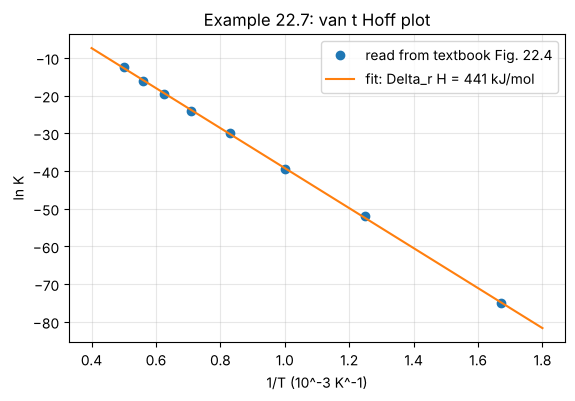

In [6]:
# 교재 그림 22.4 아래 패널에서 읽은 근사값: (1/T [1/K], ln K)
data = np.array([[5.0e-4, -12.5], [5.6e-4, -16], [6.25e-4, -19.5], [7.1e-4, -24],
                 [8.3e-4, -30], [1.0e-3, -39.5], [1.25e-3, -52], [1.67e-3, -75]])
slope, intercept = np.polyfit(data[:, 0], data[:, 1], 1)
dH = -slope * R                                   # [J/mol]
compare('Delta_r H (kJ/mol)', dH / 1e3, 440, 'kJ/mol', rtol=0.05)
compare('bond energy per molecule (eV)', dH / (NA * e), 4.5, 'eV', rtol=0.05)
print(f'intercept Delta_r S / R = {intercept:.2f}')
x = np.linspace(4e-4, 1.8e-3, 100)
plt.plot(data[:, 0] * 1e3, data[:, 1], 'o', label='read from textbook Fig. 22.4')
plt.plot(x * 1e3, slope * x + intercept, '-', label=f'fit: Delta_r H = {dH/1e3:.0f} kJ/mol')
plt.xlabel('1/T (10^-3 K^-1)'); plt.ylabel('ln K'); plt.legend(); plt.title('Example 22.7: van t Hoff plot'); plt.show()

**해석.** 맞춘 기울기에서 $\Delta_rH^\ominus\approx441$ kJ mol⁻¹, 분자당 약 4.57 eV가 나와 교재 값(약 440 kJ mol⁻¹, 4.5 eV)과 맞는다. 데이터는 그림에서 읽은 근사값이라 몇 kJ mol⁻¹ 차이는 자연스럽다.
기울기가 음수이므로 $\Delta_rH^\ominus>0$(흡열)이고, 온도가 높을수록 해리가 잘 된다.

## 예제 22.8 — 라울 법칙과 삼투압 (교재 334–335쪽)

**문제 요약.** 용질 B가 섞인 용매 A의 화학 퍼텐셜은 $\mu_A^{(\ell)}=\mu_A^{(\ell)*}+RT\ln x_A$ (22.95)로 낮아진다. 이 차이를 압력 $\Pi$로 메우면 $\Pi V_A=-RT\ln x_A$ (22.99)이고, 묽은 용액에서 $\Pi V_A\approx RTx_B$ (22.100), 곧 $\Pi V=n_BRT$ (22.101)이다.

**풀이 아이디어.** 정확한 식 (22.99)와 묽은 용액 근사 (22.100)를 $x_B$에 따라 비교한다. $V_A$는 물의 몰부피 $18.0\times10^{-6}$ m³/mol, $T=298$ K로 둔다(입력값).

x_B =  0.001: Pi exact =     1.359 atm, dilute approx =     1.359 atm, rel. diff = 0.05%
x_B =  0.010: Pi exact =    13.653 atm, dilute approx =    13.585 atm, rel. diff = 0.50%
x_B =  0.100: Pi exact =   143.133 atm, dilute approx =   135.851 atm, rel. diff = 5.09%


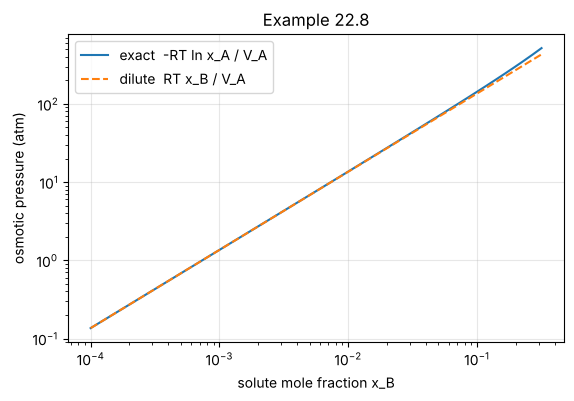

In [7]:
T = 298.0; VA = 18.0e-6                          # [K], 물의 몰부피 [m^3/mol] (입력값)
xB = np.logspace(-4, -0.5, 50)
Pi_exact = -R * T * np.log(1 - xB) / VA          # (22.99)
Pi_dilute = R * T * xB / VA                      # (22.100)
for x in (1e-3, 1e-2, 0.1):
    ex, di = -R * T * np.log(1 - x) / VA, R * T * x / VA
    print(f'x_B = {x:6.3f}: Pi exact = {ex / 101325:9.3f} atm, dilute approx = {di / 101325:9.3f} atm, rel. diff = {(ex - di) / ex:.2%}')
plt.loglog(xB, Pi_exact / 101325, label='exact  -RT ln x_A / V_A')
plt.loglog(xB, Pi_dilute / 101325, '--', label='dilute  RT x_B / V_A')
plt.xlabel('solute mole fraction x_B'); plt.ylabel('osmotic pressure (atm)'); plt.legend(); plt.title('Example 22.8'); plt.show()

**해석.** 묽은 용액($x_B\lesssim10^{-2}$)에서는 두 식이 0.5 % 안에서 같아 반트호프 식 $\Pi V=n_BRT$가 성립한다. 몰분율 1 %만 녹아 있어도 삼투압이 10 atm을 넘을 만큼 크다.

## 추가 문제 — 연습문제 22.6: 수소의 이온화 (사하 식, 교재 339쪽)

**문제 요약.** H ⇌ p⁺ + e⁻ 평형에서 $\dfrac{y^2}{1-y}=\dfrac{e^{-\beta R}}{n\lambda_{th}^3}$ (22.108)이다. 여기서 $y=n_p/n$, $R=13.6$ eV, $\lambda_{th}$는 전자의 열적 파장이다. (b) $T=1000$ K, $n=10^{20}$ m⁻³에서 이온화 정도 $y$를 구하고, (c) 밀도가 낮을수록 $y$가 커지는 이유를 본다. 교재에 수치 답은 없다.

**풀이 아이디어.** 이차방정식 $y^2+Ay-A=0$ ($A$=우변)을 풀어 $y$를 구한다. 작은 $y$에서는 $y\approx\sqrt A$.

T = 1000 K, n = 1e20 m^-3: lambda_e = 2.357e-09 m, RHS = 2.197e-63, y = 4.687e-32


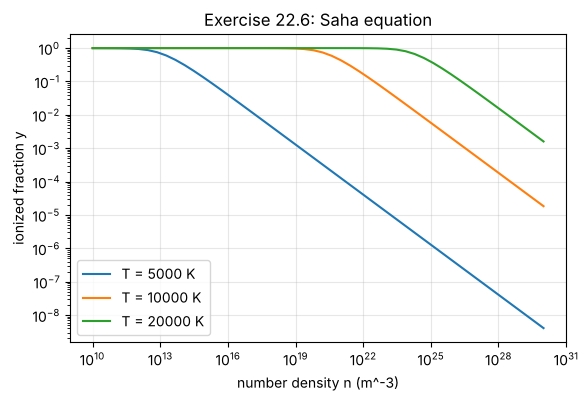

In [8]:
def ionization(T, n):
    lam_e = h / np.sqrt(2 * np.pi * me * kB * T)
    A = np.exp(-13.6 * e / (kB * T)) / (n * lam_e**3)     # (22.108) 우변
    y = (-A + np.sqrt(A * A + 4 * A)) / 2                   # y^2 + A y - A = 0
    return y, A, lam_e
y, A, lam_e = ionization(1000.0, 1e20)
print(f'T = 1000 K, n = 1e20 m^-3: lambda_e = {lam_e:.3e} m, RHS = {A:.3e}, y = {y:.3e}')
ns = np.logspace(10, 30, 50)
for T in (5000, 10000, 20000):
    plt.loglog(ns, [ionization(T, n)[0] for n in ns], label=f'T = {T} K')
plt.xlabel('number density n (m^-3)'); plt.ylabel('ionized fraction y'); plt.legend(); plt.title('Exercise 22.6: Saha equation'); plt.show()

**해석.** 1000 K에서는 $e^{-13.6\,{\rm eV}/k_BT}\approx10^{-69}$이라 이온화 정도가 $y\sim10^{-32}$로 사실상 0이다.
같은 온도에서 밀도가 낮을수록 $y$가 커지는데, 전자와 양성자가 다시 만나 결합할 확률이 줄기 때문이다(우변이 $1/n$에 비례). 엔트로피 관점에서는 입자 수가 늘어나는 이온화가 묽은 기체에서 더 유리하다.

## 추가 문제 — 연습문제 22.7: 생리식염수의 삼투압 (교재 339쪽)

**문제 요약.** 0.9 wt% NaCl 수용액은 혈액과 등삼투이다. 이 용액의 삼투압이 약 8 atm임을 보인다(교재가 제시한 목표값).

**풀이 아이디어.** 반트호프 식 $\Pi=c_BRT$ (22.101). **가정:** 용액 1 L ≈ 1 kg에 NaCl 9 g, 몰질량 58.44 g/mol, NaCl은 Na⁺와 Cl⁻로 완전히 해리(입자 수 2배), 체온 $T=310$ K.

In [9]:
mass_NaCl, M_NaCl = 9.0, 58.44            # [g], [g/mol]
n_particles = 2 * mass_NaCl / M_NaCl       # [mol] (해리로 2배)
c = n_particles / 1e-3                     # [mol/m^3] (용액 1 L)
T = 310.0
Pi = c * R * T                             # [Pa]
print(f'solute particles = {n_particles:.4f} mol per litre,  Pi = {Pi:.3e} Pa = {Pi / 101325:.2f} atm')
compare('osmotic pressure (atm)', Pi / 101325, 8.0, 'atm', rtol=0.05)

solute particles = 0.3080 mol per litre,  Pi = 7.939e+05 Pa = 7.84 atm
osmotic pressure (atm): computed = 7.835 atm | textbook = 8 atm | rel. diff = 2.06% [OK]


0.020619219002919742

**해석.** 이온 두 개로 해리하는 것을 반영하면 삼투압은 약 7.8 atm으로 교재의 "약 8 atm"과 맞는다. 해리를 빼먹으면 절반인 약 3.9 atm이 나온다.